[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_5_Regresion_Logistica_DILI.ipynb)

# Fase 5. Regresión logística para la clase DILI

En esta fase uso la etiqueta DILI como variable binaria: 1 indica clasificación positiva y 0 negativa. Considero los descriptores numéricos de RDKit, excepto MolLogP y LipinskiViolations. Selecciono en entrenamiento hasta doce variables con mayor asociación bivariada con DILI y retiro las que tienen correlación absoluta de Spearman de 0,90 o más. Estandarizo los predictores con parámetros aprendidos en train, evalúo el modelo en test y represento los odds ratios con intervalos de confianza.

In [1]:
# Instalo las librerías que usaré para la regresión y su gráfico de odds ratios.\n%pip -q install statsmodels forestplot

## 5.1. Lectura de los datos

In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
datos = dilist.merge(estructuras, on='CompoundName', how='left')  # Uno las etiquetas con el estado de búsqueda.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /workspace/scratch/b597cb51ba0f/run_outputs/datos_dili
Descriptores numéricos disponibles: 218


## 5.2. Preparación y ajuste

Reduzco la redundancia entre predictores con información de entrenamiento. Ajusto la imputación y la estandarización usando únicamente train, y aplico el mismo ajuste a test.

In [3]:
# Importo herramientas para preparar y ajustar la regresión logística.
from sklearn.impute import SimpleImputer  # Completo posibles valores ausentes.
from sklearn.preprocessing import StandardScaler  # Estandarizo los predictores.
import statsmodels.api as sm  # Ajusto el modelo y obtengo intervalos y valores p.

# Selecciono descriptores sin MolLogP ni incumplimientos que dependen de esa variable.
columnas_excluir = ['MolLogP', 'LipinskiViolations', 'DILI', 'DILIST_ID']  # Evito LogP, la clase y los identificadores.
predictores = [variable for variable in DESCRIPTORES if variable not in columnas_excluir and train_df[variable].nunique(dropna=True) > 1]  # Uso descriptores no constantes.
print('Descriptores candidatos:', len(predictores))  # Informo el tamaño inicial del catálogo.

# Reviso las asociaciones bivariadas con DILI usando solo entrenamiento.
asociacion = train_df[predictores + ['DILI']].corr(method='spearman')['DILI'].drop('DILI').dropna().abs().sort_values(ascending=False)  # Ordeno la asociación absoluta.
candidatos = asociacion.head(12).index.tolist()  # Limito el modelo a doce candidatos para mantener un modelo manejable.
print('Candidatos con mayor asociación a DILI:', len(candidatos))  # Muestro el número seleccionado.

# Quito variables redundantes entre los candidatos.
correlacion = train_df[candidatos].corr(method='spearman').abs()  # Calculo correlación absoluta.
seleccionados = []  # Creo la lista de predictores finales.
for variable in candidatos:  # Reviso candidatos en orden de asociación.
    if not any(correlacion.loc[variable, otra] >= 0.90 for otra in seleccionados):  # Compruebo redundancia.
        seleccionados.append(variable)  # Conservo variables por debajo del umbral.
print('Descriptores que usaré:', seleccionados)  # Informo el conjunto final.

# Preparo la variable objetivo y ajusto transformaciones usando solo train.
y_train = train_df['DILI'].astype(int)  # Defino las etiquetas de entrenamiento.
y_test = test_df['DILI'].astype(int)  # Defino las etiquetas de prueba.
imputador = SimpleImputer(strategy='median')  # Creo imputación por mediana.
imputador.fit(train_df[seleccionados])  # Aprendo medianas solo en train.
X_train_imp = imputador.transform(train_df[seleccionados])  # Transformo train.
X_test_imp = imputador.transform(test_df[seleccionados])  # Aplico medianas de train a test.
escalador = StandardScaler()  # Creo el escalador.
escalador.fit(X_train_imp)  # Aprendo medias y desviaciones solo con train.
X_train = escalador.transform(X_train_imp)  # Estandarizo train.
X_test = escalador.transform(X_test_imp)  # Transformo test con el mismo ajuste.

# Organizo las matrices con nombres para interpretar cada coeficiente.
X_train_df = pd.DataFrame(X_train, columns=seleccionados, index=train_df.index)  # Etiqueto las columnas de train.
X_test_df = pd.DataFrame(X_test, columns=seleccionados, index=test_df.index)  # Etiqueto las columnas de test.
X_train_sm = sm.add_constant(X_train_df, has_constant='add')  # Añado el intercepto.
X_test_sm = sm.add_constant(X_test_df, has_constant='add')  # Añado el mismo intercepto a test.

# Pondero las clases de train para compensar su distinta frecuencia.
pesos = np.where(y_train == 1, len(y_train) / (2 * (y_train == 1).sum()), len(y_train) / (2 * (y_train == 0).sum()))  # Calculo pesos equilibrados.
modelo = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial(), freq_weights=pesos).fit()  # Ajusto regresión logística ponderada.


Descriptores candidatos: 211
Candidatos con mayor asociación a DILI: 12
Descriptores que usaré: ['FractionCSP3', 'BCUT2D_LOGPLOW', 'fr_Al_OH', 'SMR_VSA6', 'SlogP_VSA2', 'fr_Ndealkylation1', 'BCUT2D_MRHI', 'fr_quatN', 'PEOE_VSA1', 'NumAtomStereoCenters', 'VSA_EState9', 'BCUT2D_CHGLO']


## 5.3. Evaluación e interpretación

Presento la matriz de confusión, accuracy, precision, recall, F1 y AUC-ROC. Para interpretar los predictores, calculo odds ratios, intervalos de confianza del 95 % y valores p, y los represento con un forest plot. La interpretación se refiere a asociaciones en estos datos, no a causalidad.


Matriz de confusión, filas reales y columnas predichas:
[[45 46]
 [57 89]]
Cada odds ratio corresponde a un aumento de una desviación estándar del descriptor, manteniendo los demás constantes.
Si el intervalo cruza 1, los datos no muestran una asociación clara al nivel del 5 % en este modelo.
Los valores p son exploratorios porque los predictores se seleccionaron previamente con train.


,valor
accuracy,0.565
precision,0.659
recall,0.610
F1,0.633
AUC-ROC,0.579


,descriptor,odds_ratio,ic_inferior,ic_superior,p_value
0,FractionCSP3,0.6813,0.5713,0.8126,0.0000
9,NumAtomStereoCenters,2.5862,1.6161,4.1387,0.0001
5,fr_Ndealkylation1,0.7537,0.6405,0.8869,0.0007
6,BCUT2D_MRHI,1.2592,1.0756,1.4740,0.0041
8,PEOE_VSA1,0.4331,0.2119,0.8851,0.0218
1,BCUT2D_LOGPLOW,1.3370,0.9880,1.8094,0.0599
7,fr_quatN,0.8026,0.6240,1.0323,0.0869
2,fr_Al_OH,0.8420,0.6759,1.0488,0.1248
3,SMR_VSA6,1.1407,0.8713,1.4933,0.3382
10,VSA_EState9,0.9462,0.8027,1.1152,0.5095


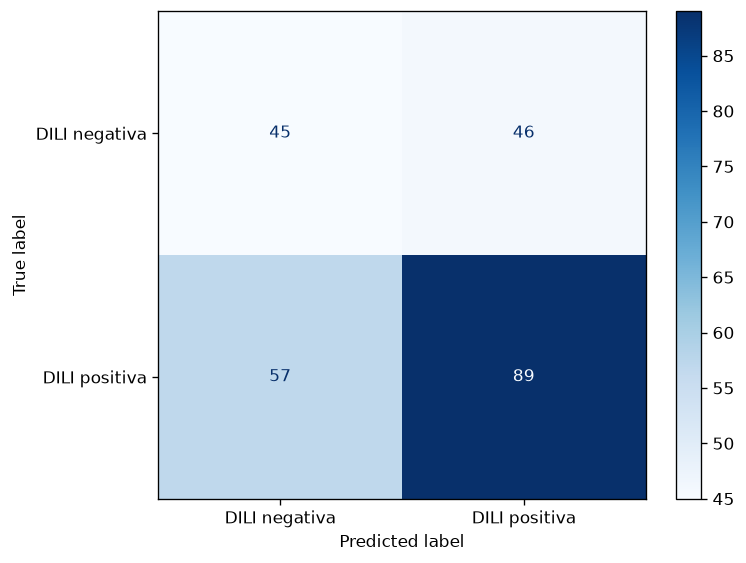

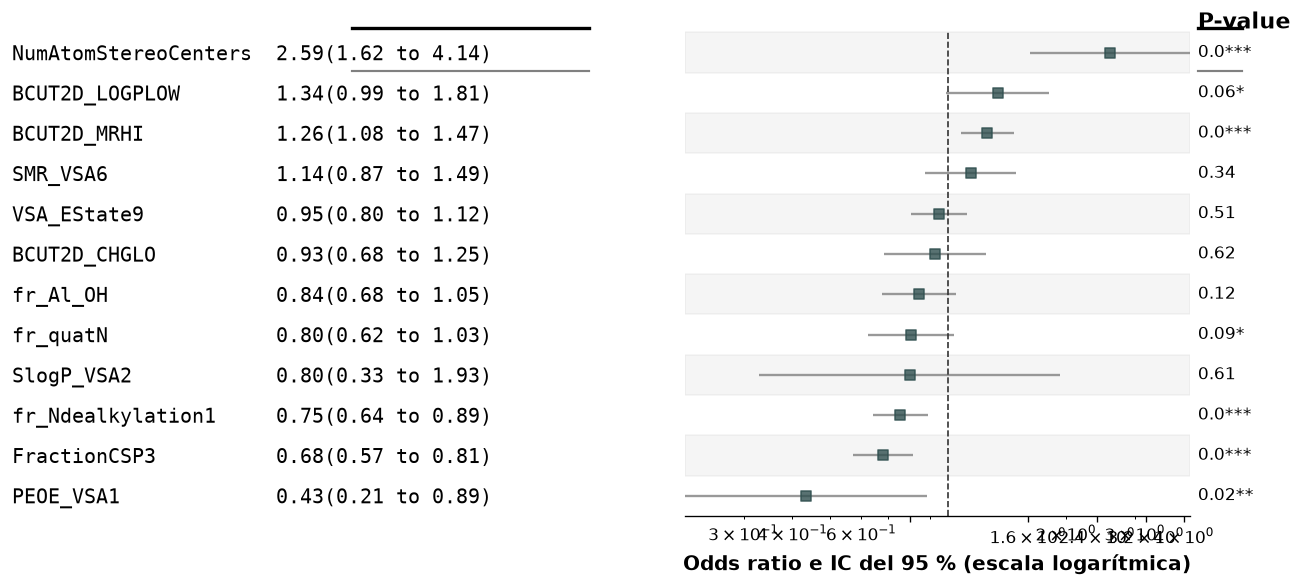

In [4]:
import matplotlib.pyplot as plt  # Dibujo la evaluación del modelo.
# Importo las métricas para evaluar la clasificación.
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay  # Cargo medidas de evaluación.

# Calculo las clases y probabilidades predichas para test.
probabilidad = modelo.predict(X_test_sm)  # Estimo la probabilidad de DILI positiva.
prediccion = (probabilidad >= 0.5).astype(int)  # Clasifico con un umbral de 0,5.
matriz = confusion_matrix(y_test, prediccion, labels=[0, 1])  # Calculo verdaderos y falsos positivos/negativos.
metricas = {'accuracy': accuracy_score(y_test, prediccion), 'precision': precision_score(y_test, prediccion, zero_division=0), 'recall': recall_score(y_test, prediccion, zero_division=0), 'F1': f1_score(y_test, prediccion, zero_division=0), 'AUC-ROC': roc_auc_score(y_test, probabilidad)}  # Calculo indicadores de clasificación.
print('Matriz de confusión, filas reales y columnas predichas:')  # Explico el formato.
print(matriz)  # Muestro la matriz.
display(pd.Series(metricas, name='valor').to_frame().round(3))  # Muestro las métricas.

# Visualizo la matriz de confusión con sus etiquetas.
ConfusionMatrixDisplay(matriz, display_labels=['DILI negativa', 'DILI positiva']).plot(cmap='Blues')  # Represento los cuatro resultados.
plt.tight_layout()  # Ajusto la visualización.
plt.show()  # Muestro la figura.

# Expreso cada coeficiente como odds ratio e intervalo de confianza del 95 %.
intervalos = modelo.conf_int().loc[seleccionados]  # Extraigo los intervalos de los descriptores.
odds = pd.DataFrame({'descriptor': seleccionados, 'odds_ratio': np.exp(modelo.params.loc[seleccionados].values), 'ic_inferior': np.exp(intervalos[0].values), 'ic_superior': np.exp(intervalos[1].values), 'p_value': modelo.pvalues.loc[seleccionados].values})  # Organizo el efecto y su incertidumbre.
display(odds.sort_values('p_value').round(4))  # Muestro primero los menores valores p.

# Dibujo los odds ratios con forestplot y marco el valor nulo OR = 1.
import forestplot as fp  # Cargo la librería enlazada en el proyecto.
figura, eje = plt.subplots(figsize=(11, max(5, 0.38 * len(odds))))  # Ajusto la altura al número de variables.
fp.forestplot(dataframe=odds, estimate='odds_ratio', ll='ic_inferior', hl='ic_superior', varlabel='descriptor', pval='p_value', logscale=True, sort=True, xlabel='Odds ratio e IC del 95 % (escala logarítmica)', color_alt_rows=True, xline=1, xlinestyle='--', table=True, ax=eje)  # Muestro estimaciones, intervalos y valores p.
plt.tight_layout()  # Ajusto etiquetas y tabla.
plt.show()  # Presento el forest plot.
print('Cada odds ratio corresponde a un aumento de una desviación estándar del descriptor, manteniendo los demás constantes.')  # Interpreto la escala.
print('Si el intervalo cruza 1, los datos no muestran una asociación clara al nivel del 5 % en este modelo.')  # Explico el valor nulo.
print('Los valores p son exploratorios porque los predictores se seleccionaron previamente con train.')  # Aclaro el efecto de selección.


## Lectura del resultado

Valoro el recall de la clase positiva junto con precision y F1, porque un único porcentaje de accuracy podría ocultar errores en una clase. Reviso también AUC-ROC y la matriz de confusión. El forest plot presenta los odds ratios, sus intervalos de confianza del 95 % y los valores p. Como las variables están estandarizadas, cada odds ratio describe el cambio asociado a una desviación estándar del descriptor, manteniendo constantes los demás. Los intervalos que cruzan OR = 1 no muestran una asociación clara al nivel del 5 %. La selección previa de variables hace que estos valores p sean exploratorios.
